# Ablation V3 — CNN + SLIC-Graph GCN Baseline

## Prostate Cancer Detection · H&E Histopathology (DiagSet Binary)

**Journal Retrain — matched to Hybrid / LGCN / GAT / JGCN retrain protocol**

Purpose of V3: measure the contribution of the SLIC-graph GCN branch on top of the CNN-only baseline (V1), *before* the batch-level GAT or the SE-gated fusion are added. Architecturally identical to "Hybrid minus GAT branch minus SE gate", so V3 vs V1 isolates the effect of adding the GCN branch under plain concatenation fusion.

- **Architecture**: EfficientNet-B4 (blocks 0-4 frozen) → cnn_proj (1792 → 512) + 3-layer GCN on SLIC superpixels (8 → 256 → 128 → 64) → concat (512 + 64 = 576) → classifier (576 → 512 → 128 → 2)
- **No batch-level GAT branch, no SE fusion gate.**
- **Graph cache**: reuses Hybrid's `<repo>/cache\graph_cache.pkl` (75 SLIC superpixels, kNN k=5, 8-dim node features)
- **Local paths**: `<repo>/results\Ablation_V3\`
- **Environment**: `abide` conda env (torch 2.5.1+cu121, PyG 2.8.0, CUDA 12.1)
- **Hardware**: RTX 3060 12 GB

**Matched protocol vs V1 / V2 / Hybrid / LGCN / GAT / JGCN**
- 80 epochs, patience 15 on validation AUC-ROC
- Focal Loss (γ=2.0, α=0.75)
- AdamW differential LRs (backbone 1×10⁻⁴, head 3×10⁻⁴), weight decay 1×10⁻⁴
- CosineAnnealingWarmRestarts (T₀=10, T_mult=2)
- MixUp α=0.2 on 50% of batches, TrivialAugment, RandomErasing p=0.25
- WeightedRandomSampler, TTA×5 at inference (fp32)
- seed=42, image-level 70/15/15 stratified split (identical 901-patch test set)

**Artefacts produced (Cell 6B)**
- `v3_predictions.npz` — y_true / y_pred / y_prob (non-TTA & TTA) + 576-dim fused features
- `v3_history.json` — full epoch-by-epoch metrics
- `v3_env.json` — reproducibility fingerprint
- `checkpoints_backup/` — local copy of all four artefacts

**Bug fixes carried into V3 (from V1/V2)**
- Val-loop lists renamed `v_probs, v_labels` (no dataset-array collision)
- Cell 6 reads test paths/labels from `test_ds` attributes directly


## CELL 1B — Local PC Setup

In [ ]:
# Resolve the repository root so this notebook runs from a clean clone.
import os
REPO_ROOT = os.getcwd()
while not os.path.exists(os.path.join(REPO_ROOT, 'config.py')):
    parent = os.path.dirname(REPO_ROOT)
    if parent == REPO_ROOT:
        raise RuntimeError('config.py not found - run this notebook from inside the repository')
    REPO_ROOT = parent
print('REPO_ROOT:', REPO_ROOT)


In [1]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 1B — Local PC Setup                                     ║
# ╚══════════════════════════════════════════════════════════════╝
import os

WORK_DIR   = os.path.join(REPO_ROOT, 'runs', 'ablation_v3')
DATA_ROOT  = REPO_ROOT
DRIVE_ROOT = DATA_ROOT

os.makedirs(WORK_DIR, exist_ok=True)
assert os.path.isdir(WORK_DIR), f'Folder not found: {WORK_DIR}'

print('Work directory  :', WORK_DIR)
print('Files in folder :')
for f in sorted(os.listdir(WORK_DIR)):
    print('  •', f)


Work directory  : <repo>/results\Ablation_V3
Files in folder :


## CELL 1 — Environment check

In [2]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 1 — Environment check                                   ║
# ║   V3 needs PyG (for GCNConv) — abide env has it              ║
# ╚══════════════════════════════════════════════════════════════╝
import torch, sys
print('Python  :', sys.version.split()[0])
print('Torch   :', torch.__version__)
print('CUDA    :', torch.version.cuda)
print('GPU     :', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu')
import torchvision, timm, torch_geometric
print('torchvision     :', torchvision.__version__)
print('timm            :', timm.__version__)
print('torch_geometric :', torch_geometric.__version__)


Python  : 3.10.20
Torch   : 2.5.1+cu121
CUDA    : 12.1
GPU     : NVIDIA GeForce RTX 3060
torchvision     : 0.20.1+cu121
timm            : 1.0.9
torch_geometric : 2.5.3


## CELL 2 — Imports and Config (LOCAL paths)

In [3]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 2 — Imports and Config                                  ║
# ║   V3 architecture: CNN branch + 3-layer SLIC-graph GCN       ║
# ║   Loads Hybrid's existing graph_cache.pkl (no rebuild)       ║
# ╚══════════════════════════════════════════════════════════════╝
import os, random, warnings, pickle, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm import tqdm
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as T
import timm

from torch_geometric.nn import GCNConv, global_mean_pool
from torch_geometric.data import Data, Batch

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, confusion_matrix, classification_report,
    matthews_corrcoef, roc_curve, precision_recall_curve, average_precision_score
)
warnings.filterwarnings('ignore')

def denormalize(img_tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])
    img  = img_tensor.cpu().numpy().transpose(1, 2, 0)
    return np.clip(img * std + mean, 0, 1)

CONFIG = {
    # ── LOCAL PATHS ──
    'data_dir'         : os.path.join(REPO_ROOT, 'dataset'),
    'output_dir'       : WORK_DIR,
    'graph_cache_path' : os.path.join(REPO_ROOT, 'cache', 'graph_cache.pkl'),
    'model_save_path'  : os.path.join(WORK_DIR, 'best_v3_model.pth'),

    # ── Image ──
    'img_size'         : 224,

    # ── V3 architecture (identical to Hybrid GCN branch) ──
    'cnn_proj_dim'     : 512,
    'gcn_hidden_dim'   : 256,
    'gcn_node_in_dim'  : 8,
    'head_hidden_dim'  : 128,
    'dropout'          : 0.4,
    'num_classes'      : 2,

    # ── Training (MATCHED to V1 / V2 / Hybrid) ──
    'batch_size'       : 32,
    'num_epochs'       : 80,
    'lr_backbone'      : 1e-4,
    'lr_head'          : 3e-4,
    'weight_decay'     : 1e-4,
    'patience'         : 15,
    'focal_gamma'      : 2.0,
    'focal_alpha'      : 0.75,
    'seed'             : 42,
    'train_split'      : 0.70,
    'val_split'        : 0.15,
    'test_split'       : 0.15,
    'num_workers'      : 0,
    'mixup_alpha'      : 0.2,
    'mixup_prob'       : 0.5,
    'erase_prob'       : 0.25,
    'tta_n'            : 5,
    'use_amp'          : False,
}
SEED = CONFIG['seed']
MODEL_PATH = CONFIG['model_save_path']

def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
os.makedirs(CONFIG['output_dir'], exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('=' * 60)
print('  ABLATION V3: CNN + SLIC-GRAPH GCN')
print('  Journal Retrain — matched protocol')
print('=' * 60)
print(f'  Device      : {DEVICE}')
if torch.cuda.is_available():
    print(f'  GPU         : {torch.cuda.get_device_name(0)}')
print(f'  Epochs      : {CONFIG["num_epochs"]}  |  Patience : {CONFIG["patience"]}')
print(f'  GCN         : 3-layer, hidden {CONFIG["gcn_hidden_dim"]} -> 128 -> 64')
print(f'  Fusion      : concat (512 + 64 = 576)   -- NO SE gate')
print(f'  Graph cache : {CONFIG["graph_cache_path"]}')
print(f'  Model out   : {CONFIG["model_save_path"]}')
print('=' * 60)


  ABLATION V3: CNN + SLIC-GRAPH GCN
  Journal Retrain — matched protocol
  Device      : cuda
  GPU         : NVIDIA GeForce RTX 3060
  Epochs      : 80  |  Patience : 15
  GCN         : 3-layer, hidden 256 -> 128 -> 64
  Fusion      : concat (512 + 64 = 576)   -- NO SE gate
  Graph cache : <repo>/cache\graph_cache.pkl
  Model out   : <repo>/results\Ablation_V3\best_v3_model.pth


## CELL 3 — Dataset (with SLIC graphs) + Split + Loaders

In [4]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 3 — Dataset + Split + Loaders (graph-aware)             ║
# ║   Loads Hybrid's existing graph_cache.pkl                    ║
# ║   Each sample returns (img_tensor, label, graph_data)        ║
# ╚══════════════════════════════════════════════════════════════╝
IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}

# ── Load pre-built graph cache (reuse from Hybrid retrain) ──
print(f'Loading graph cache from: {CONFIG["graph_cache_path"]}')
with open(CONFIG['graph_cache_path'], 'rb') as f:
    graph_cache = pickle.load(f)
print(f'  Loaded {len(graph_cache):,} cached graphs')
sample_key = next(iter(graph_cache))
sample_val = graph_cache[sample_key]
print(f'  Sample entry keys : {list(sample_val.keys())}')
print(f'  x.shape           : {np.asarray(sample_val["x"]).shape}   (expected [n_nodes, 8])')
print(f'  edge_index.shape  : {np.asarray(sample_val["edge_index"]).shape}   (expected [2, ~n_nodes*k])')

class ProstateGCNDataset(Dataset):
    def __init__(self, file_list, labels, transform, graph_cache):
        self.file_list   = file_list
        self.labels      = labels
        self.transform   = transform
        self.graph_cache = graph_cache
    def __len__(self):
        return len(self.file_list)
    def __getitem__(self, idx):
        p     = self.file_list[idx]
        label = int(self.labels[idx])
        img_t = self.transform(Image.open(p).convert('RGB'))
        cached = self.graph_cache.get(p)
        if cached is not None:
            graph = Data(
                x=torch.tensor(cached['x'], dtype=torch.float),
                edge_index=torch.tensor(cached['edge_index'], dtype=torch.long),
                y=torch.tensor(label, dtype=torch.long),
            )
        else:
            graph = None
        return img_t, torch.tensor(label, dtype=torch.long), graph

def collate_fn(batch):
    imgs   = torch.stack([b[0] for b in batch])
    labels = torch.stack([b[1] for b in batch])
    graphs = [b[2] for b in batch if b[2] is not None]
    gbatch = Batch.from_data_list(graphs) if graphs else None
    return imgs, labels, gbatch

# ── Canonical file listing (same as baselines) ──────────────
data_dir = Path(CONFIG['data_dir'])
all_paths, all_labels = [], []
for label_idx, cls in enumerate(['Benign', 'Malignant']):
    class_dir = data_dir / cls
    files = [pp for pp in class_dir.iterdir() if pp.suffix.lower() in IMG_EXTS]
    all_paths.extend([str(pp) for pp in files])
    all_labels.extend([label_idx] * len(files))
    print(f'  {cls:12s}: {len(files):5d} images')

all_paths  = np.array(all_paths)
all_labels = np.array(all_labels)
print(f'  Total       : {len(all_paths)}')

idx = np.arange(len(all_paths))
train_idx, temp_idx = train_test_split(
    idx, test_size=0.30, stratify=all_labels, random_state=SEED)
val_idx, test_idx   = train_test_split(
    temp_idx, test_size=0.50,
    stratify=all_labels[temp_idx], random_state=SEED)
print(f'  Train : {len(train_idx)}   Val : {len(val_idx)}   Test : {len(test_idx)}')

# Sanity: cache hit rate on splits
def hit_rate(paths):
    return sum(1 for p in paths if p in graph_cache) / max(1, len(paths))
print(f'  Graph-cache hit rate: '
      f'train {hit_rate(all_paths[train_idx])*100:.1f}%  '
      f'val {hit_rate(all_paths[val_idx])*100:.1f}%  '
      f'test {hit_rate(all_paths[test_idx])*100:.1f}%')

# ── Transforms (identical to V1 / V2 / Hybrid) ──────────────
train_tf = T.Compose([
    T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation(15),
    T.TrivialAugmentWide(),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    T.RandomErasing(p=CONFIG['erase_prob'], scale=(0.02, 0.10), ratio=(0.3, 3.3)),
])
eval_tf = T.Compose([
    T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class TTAWrap:
    def __init__(self, base_tf):
        self.base = base_tf
    def __call__(self, img):
        return [
            self.base(img),
            self.base(img.transpose(Image.FLIP_LEFT_RIGHT)),
            self.base(img.transpose(Image.FLIP_TOP_BOTTOM)),
            self.base(img.rotate(90)),
            self.base(img.rotate(270)),
        ]
tta_tf = TTAWrap(eval_tf)

train_ds = ProstateGCNDataset(all_paths[train_idx].tolist(),
                               all_labels[train_idx].tolist(),
                               train_tf, graph_cache)
val_ds   = ProstateGCNDataset(all_paths[val_idx].tolist(),
                               all_labels[val_idx].tolist(),
                               eval_tf, graph_cache)
test_ds  = ProstateGCNDataset(all_paths[test_idx].tolist(),
                               all_labels[test_idx].tolist(),
                               eval_tf, graph_cache)

train_labels_arr = all_labels[train_idx]
class_counts = np.bincount(train_labels_arr, minlength=2)
class_weights = 1.0 / class_counts
sample_weights = class_weights[train_labels_arr]
train_sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(sample_weights),
    replacement=True)

train_loader = DataLoader(train_ds, batch_size=CONFIG['batch_size'],
                           sampler=train_sampler, num_workers=CONFIG['num_workers'],
                           collate_fn=collate_fn)
val_loader   = DataLoader(val_ds,   batch_size=CONFIG['batch_size'],
                           shuffle=False, num_workers=CONFIG['num_workers'],
                           collate_fn=collate_fn)
test_loader  = DataLoader(test_ds,  batch_size=CONFIG['batch_size'],
                           shuffle=False, num_workers=CONFIG['num_workers'],
                           collate_fn=collate_fn)

print(f'  Train sampler: WeightedRandomSampler (inverse class frequency)')
print(f'  Class counts : {dict(zip(["Benign","Malignant"], class_counts.tolist()))}')


Loading graph cache from: <repo>/cache\graph_cache.pkl
  Loaded 6,002 cached graphs
  Sample entry keys : ['x', 'edge_index']
  x.shape           : (71, 8)   (expected [n_nodes, 8])
  edge_index.shape  : (2, 410)   (expected [2, ~n_nodes*k])
  Benign      :  3000 images
  Malignant   :  3002 images
  Total       : 6002
  Train : 4201   Val : 900   Test : 901
  Graph-cache hit rate: train 100.0%  val 100.0%  test 100.0%
  Train sampler: WeightedRandomSampler (inverse class frequency)
  Class counts : {'Benign': 2100, 'Malignant': 2101}


## CELL 4 — V3 Model Architecture (CNN + GCN)

In [5]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 4 — V3 Model                                            ║
# ║   Identical to Hybrid minus GAT branch minus SE gate         ║
# ║   GCN branch: 3 layers on SLIC superpixels                   ║
# ╚══════════════════════════════════════════════════════════════╝
class CNN_GCN_ProstateClassifier(nn.Module):
    def __init__(self, num_classes=2, proj_dim=512, gcn_hidden=256,
                 gcn_node_in=8, head_dim=128, dropout=0.4):
        super().__init__()
        H = gcn_hidden

        # Backbone
        self.backbone = timm.create_model('efficientnet_b4', pretrained=True,
                                           num_classes=0, global_pool='avg')
        cnn_dim = self.backbone.num_features  # 1792

        blocks_to_freeze = ['blocks.0', 'blocks.1', 'blocks.2', 'blocks.3',
                            'conv_stem', 'bn1']
        for name, param in self.backbone.named_parameters():
            if any(b in name for b in blocks_to_freeze):
                param.requires_grad = False

        # CNN projection (identical to Hybrid / V1 / V2)
        self.cnn_proj = nn.Sequential(
            nn.Linear(cnn_dim, proj_dim),
            nn.BatchNorm1d(proj_dim),
            nn.ReLU(),
            nn.Dropout(dropout * 0.5))

        # GCN branch (identical to Hybrid GCN branch)
        # 8-dim node feats -> H via linear+ReLU, then 3 GCN layers with LayerNorm
        self.gcn_input_proj = nn.Sequential(nn.Linear(gcn_node_in, H), nn.ReLU())
        self.gcn1 = GCNConv(H,      H)
        self.gcn2 = GCNConv(H,      H // 2)
        self.gcn3 = GCNConv(H // 2, H // 4)
        self.gcn_norm1 = nn.LayerNorm(H)
        self.gcn_norm2 = nn.LayerNorm(H // 2)
        self.gcn_norm3 = nn.LayerNorm(H // 4)

        # Fusion: concat (no SE gate)
        gcn_out_dim = H // 4     # 64
        fusion_dim = proj_dim + gcn_out_dim   # 512 + 64 = 576

        # Classifier — mirrors Hybrid structure
        self.classifier = nn.Sequential(
            nn.Linear(fusion_dim, proj_dim),
            nn.BatchNorm1d(proj_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(proj_dim, head_dim),
            nn.BatchNorm1d(head_dim),
            nn.ReLU(),
            nn.Dropout(dropout * 0.6),
            nn.Linear(head_dim, num_classes))

        self._gcn_out_dim = gcn_out_dim

    def forward(self, imgs, graph_batch):
        B = imgs.size(0)
        cnn_feats = self.backbone(imgs)          # (B, 1792)
        cnn_out   = self.cnn_proj(cnn_feats)     # (B, 512)

        if graph_batch is not None:
            gx = self.gcn_input_proj(graph_batch.x)
            ei = graph_batch.edge_index
            gb = graph_batch.batch
            gx = self.gcn_norm1(F.relu(self.gcn1(gx, ei)))
            gx = self.gcn_norm2(F.relu(self.gcn2(gx, ei)))
            gx = self.gcn_norm3(F.relu(self.gcn3(gx, ei)))
            gcn_out = global_mean_pool(gx, gb)   # (B, 64)
        else:
            gcn_out = torch.zeros(B, self._gcn_out_dim, device=imgs.device)

        fused = torch.cat([cnn_out, gcn_out], dim=1)   # (B, 576)
        return self.classifier(fused)

model = CNN_GCN_ProstateClassifier(
    num_classes=CONFIG['num_classes'],
    proj_dim=CONFIG['cnn_proj_dim'],
    gcn_hidden=CONFIG['gcn_hidden_dim'],
    gcn_node_in=CONFIG['gcn_node_in_dim'],
    head_dim=CONFIG['head_hidden_dim'],
    dropout=CONFIG['dropout']).to(DEVICE)

n_total = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'  Total params    : {n_total:,}')
print(f'  Trainable params: {n_train:,}  ({100*n_train/n_total:.1f}%)')
print(f'  CNN freeze depth: blocks 0-4  (matched)')
print(f'  Fusion          : concat 512 + 64 = 576   (NO SE gate)')


  Total params    : 18,940,426
  Trainable params: 17,566,814  (92.7%)
  CNN freeze depth: blocks 0-4  (matched)
  Fusion          : concat 512 + 64 = 576   (NO SE gate)


## CELL 5 — Training Loop (v_probs/v_labels bug fix carried over)

In [6]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 5 — Training Loop                                       ║
# ║   Val lists renamed v_probs / v_labels (no collision)        ║
# ╚══════════════════════════════════════════════════════════════╝
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, alpha=0.75):
        super().__init__()
        self.gamma = gamma
        self.alpha = alpha
    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, reduction='none')
        pt = torch.exp(-ce)
        alpha_t = torch.where(targets == 1, self.alpha, 1 - self.alpha)
        loss = alpha_t * (1 - pt) ** self.gamma * ce
        return loss.mean()

def mixup_batch(imgs, labels, alpha=0.2):
    lam = np.random.beta(alpha, alpha)
    idx_perm = torch.randperm(imgs.size(0), device=imgs.device)
    mixed_imgs = lam * imgs + (1 - lam) * imgs[idx_perm]
    labels_a, labels_b = labels, labels[idx_perm]
    return mixed_imgs, labels_a, labels_b, lam

def mixup_focal(criterion, logits, labels_a, labels_b, lam):
    return lam * criterion(logits, labels_a) + (1 - lam) * criterion(logits, labels_b)

backbone_params = [p for n, p in model.named_parameters()
                   if 'backbone' in n and p.requires_grad]
head_params     = [p for n, p in model.named_parameters()
                   if 'backbone' not in n and p.requires_grad]
optimizer = torch.optim.AdamW([
    {'params': backbone_params, 'lr': CONFIG['lr_backbone']},
    {'params': head_params,     'lr': CONFIG['lr_head']},
], weight_decay=CONFIG['weight_decay'])

scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer, T_0=10, T_mult=2, eta_min=1e-6)

criterion = FocalLoss(gamma=CONFIG['focal_gamma'], alpha=CONFIG['focal_alpha'])

history = {'train_loss': [], 'train_acc': [],
           'val_loss': [], 'val_acc': [], 'val_auc': []}
best_val_auc = 0.0
best_val_acc = 0.0
best_epoch   = 0
patience_ctr = 0

os.makedirs(os.path.dirname(MODEL_PATH), exist_ok=True)
BACKUP_DIR = os.path.join(WORK_DIR, 'checkpoints_backup')
os.makedirs(BACKUP_DIR, exist_ok=True)

print(f'\nTraining V3 for {CONFIG["num_epochs"]} epochs (patience={CONFIG["patience"]})...')
t_start = time.time()

for epoch in range(1, CONFIG['num_epochs'] + 1):
    # ── Train ────────────────────────────────────────────
    model.train()
    tr_loss_sum, tr_correct, tr_total = 0.0, 0, 0
    for imgs, labels, gbatch in train_loader:
        imgs   = imgs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        if gbatch is not None:
            gbatch = gbatch.to(DEVICE)

        use_mixup = np.random.rand() < CONFIG['mixup_prob']
        if use_mixup:
            imgs, la, lb, lam = mixup_batch(imgs, labels, CONFIG['mixup_alpha'])

        optimizer.zero_grad()
        out = model(imgs, gbatch)
        loss = mixup_focal(criterion, out, la, lb, lam) if use_mixup \
               else criterion(out, labels)
        loss.backward()
        optimizer.step()

        tr_loss_sum += loss.item() * imgs.size(0)
        preds = out.argmax(dim=1)
        tr_correct += (preds == (la if use_mixup else labels)).sum().item()
        tr_total   += imgs.size(0)

    scheduler.step()
    train_loss = tr_loss_sum / tr_total
    train_acc  = tr_correct  / tr_total

    # ── Validate ────────────────────────────────────────
    model.eval()
    val_loss_sum, val_correct, val_total = 0.0, 0, 0
    v_probs, v_labels = [], []
    with torch.no_grad():
        for imgs, labels, gbatch in val_loader:
            imgs   = imgs.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            if gbatch is not None:
                gbatch = gbatch.to(DEVICE)
            out = model(imgs, gbatch)
            loss = criterion(out, labels)
            val_loss_sum += loss.item() * imgs.size(0)
            probs = torch.softmax(out.float(), dim=1)[:, 1]
            preds = out.argmax(dim=1)
            val_correct += (preds == labels).sum().item()
            val_total   += imgs.size(0)
            v_probs.extend(probs.cpu().numpy().tolist())
            v_labels.extend(labels.cpu().numpy().tolist())

    val_loss = val_loss_sum / val_total
    val_acc  = val_correct  / val_total
    try:
        val_auc = roc_auc_score(v_labels, v_probs)
    except Exception:
        val_auc = float('nan')

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['val_auc'].append(val_auc)

    marker = ''
    if val_auc > best_val_auc:
        best_val_auc = val_auc
        best_val_acc = val_acc
        best_epoch   = epoch
        patience_ctr = 0
        torch.save({
            'model': model.state_dict(),
            'epoch': epoch,
            'best_auc': best_val_auc,
            'best_acc': best_val_acc,
            'config':   CONFIG,
        }, MODEL_PATH)
        marker = '  ← best'
    else:
        patience_ctr += 1

    print(f'Ep {epoch:3d}/{CONFIG["num_epochs"]}   '
          f'loss {train_loss:.4f}/{val_loss:.4f}   '
          f'acc {train_acc*100:5.2f}/{val_acc*100:5.2f}%   '
          f'val_auc {val_auc:.4f}   pat {patience_ctr}/{CONFIG["patience"]}{marker}')

    if patience_ctr >= CONFIG['patience']:
        print(f'\nEarly stopping at epoch {epoch}. Best val AUC = {best_val_auc:.4f} at epoch {best_epoch}.')
        break

elapsed = (time.time() - t_start) / 60
print(f'\nTraining finished. Elapsed {elapsed:.1f} min. Best model at epoch {best_epoch}, val AUC {best_val_auc:.4f}.')



Training V3 for 80 epochs (patience=15)...
Ep   1/80   loss 0.0850/0.0689   acc 52.77/60.33%   val_auc 0.7039   pat 0/15  ← best
Ep   2/80   loss 0.0746/0.0636   acc 56.49/63.11%   val_auc 0.7565   pat 0/15  ← best
Ep   3/80   loss 0.0705/0.0592   acc 56.11/63.33%   val_auc 0.7812   pat 0/15  ← best
Ep   4/80   loss 0.0658/0.0579   acc 58.34/66.00%   val_auc 0.7991   pat 0/15  ← best
Ep   5/80   loss 0.0635/0.0551   acc 60.25/65.11%   val_auc 0.8226   pat 0/15  ← best
Ep   6/80   loss 0.0638/0.0543   acc 59.87/68.11%   val_auc 0.8364   pat 0/15  ← best
Ep   7/80   loss 0.0615/0.0531   acc 59.87/69.89%   val_auc 0.8445   pat 0/15  ← best
Ep   8/80   loss 0.0616/0.0523   acc 60.41/69.67%   val_auc 0.8466   pat 0/15  ← best
Ep   9/80   loss 0.0591/0.0514   acc 60.96/68.33%   val_auc 0.8527   pat 0/15  ← best
Ep  10/80   loss 0.0596/0.0510   acc 62.77/70.22%   val_auc 0.8569   pat 0/15  ← best
Ep  11/80   loss 0.0614/0.0511   acc 61.03/66.11%   val_auc 0.8632   pat 0/15  ← best
Ep  12/80 

## CELL 6 — Load Best Model & TTA×5 Test Evaluation

In [7]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 6 — Load Best Checkpoint & TTA×5 Test Evaluation        ║
# ╚══════════════════════════════════════════════════════════════╝
CLASS_NAMES = ['Benign', 'Malignant']

ckpt = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt['model'])
model.eval()
print(f'Loaded best model (epoch {ckpt["epoch"]}, val AUC {ckpt["best_auc"]:.4f})')

def predict_tta5(path_list, label_list, model):
    all_probs_tta, all_labels_out = [], []
    for i in range(0, len(path_list), CONFIG['batch_size']):
        batch_paths  = path_list[i:i+CONFIG['batch_size']]
        batch_labels = label_list[i:i+CONFIG['batch_size']]

        # Build per-patch graph list ONCE (identical across TTA views)
        graphs = []
        for p in batch_paths:
            cached = graph_cache.get(p)
            if cached is not None:
                g = Data(
                    x=torch.tensor(cached['x'], dtype=torch.float),
                    edge_index=torch.tensor(cached['edge_index'], dtype=torch.long))
                graphs.append(g)
        gbatch = Batch.from_data_list(graphs).to(DEVICE) if graphs else None

        view_batches = [[] for _ in range(5)]
        for p in batch_paths:
            img = Image.open(p).convert('RGB')
            views = tta_tf(img)
            for v_idx, v in enumerate(views):
                view_batches[v_idx].append(v)

        prob_sum = None
        with torch.no_grad():
            for v_idx in range(5):
                view_tensor = torch.stack(view_batches[v_idx]).to(DEVICE)
                out = model(view_tensor, gbatch)
                probs = torch.softmax(out.float(), dim=1)[:, 1]
                probs = torch.nan_to_num(probs, nan=0.5, posinf=1.0, neginf=0.0)
                prob_sum = probs if prob_sum is None else prob_sum + probs

        probs_mean = prob_sum / 5.0
        all_probs_tta.extend(probs_mean.cpu().numpy().tolist())
        all_labels_out.extend(batch_labels)
    return np.array(all_probs_tta), np.array(all_labels_out)

test_paths  = test_ds.file_list
test_labels = test_ds.labels

tta_probs, tta_labels_arr = predict_tta5(test_paths, test_labels, model)
tta_preds = (tta_probs >= 0.5).astype(int)

acc_tta  = (tta_preds == tta_labels_arr).mean()
auc_tta  = roc_auc_score(tta_labels_arr, tta_probs)
mcc_tta  = matthews_corrcoef(tta_labels_arr, tta_preds)
f1_tta   = f1_score(tta_labels_arr, tta_preds)
cm_tta   = confusion_matrix(tta_labels_arr, tta_preds)
tn, fp, fn, tp = cm_tta.ravel()
sens_tta = tp / (tp + fn) if (tp + fn) else 0
spec_tta = tn / (tn + fp) if (tn + fp) else 0

print('\n───────────── TTA×5 test results (V3) ─────────────')
print(f'  Accuracy    : {acc_tta*100:.2f}%')
print(f'  AUC-ROC     : {auc_tta:.4f}')
print(f'  MCC         : {mcc_tta:.4f}')
print(f'  F1          : {f1_tta:.4f}')
print(f'  Sensitivity : {sens_tta*100:.2f}%')
print(f'  Specificity : {spec_tta*100:.2f}%')
print(f'  CM (TN/FP/FN/TP): {tn}/{fp}/{fn}/{tp}')

all_preds_test  = tta_preds
all_probs_test  = tta_probs
all_labels_test = tta_labels_arr

v3_fpr_saved, v3_tpr_saved, _ = roc_curve(tta_labels_arr, tta_probs)
v3_auc_saved  = auc_tta
v3_acc_saved  = acc_tta


Loaded best model (epoch 67, val AUC 0.9975)

───────────── TTA×5 test results (V3) ─────────────
  Accuracy    : 95.01%
  AUC-ROC     : 0.9952
  MCC         : 0.9028
  F1          : 0.9520
  Sensitivity : 98.89%
  Specificity : 91.11%
  CM (TN/FP/FN/TP): 410/40/5/446


## CELL 6B — Full Inference Artefact Save

In [8]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 6B — Full Inference Artefact Save                       ║
# ║ Hook on classifier[0] captures the 576-dim fused features    ║
# ║ (CNN 512 + GCN 64, no SE gate)                               ║
# ╚══════════════════════════════════════════════════════════════╝
import json, platform, sys, shutil
from datetime import datetime

ckpt = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt['model'])
model.eval()

fused_feats = []
def _hook(module, inp, out):
    fused_feats.append(inp[0].detach().cpu().numpy())
hook = model.classifier[0].register_forward_hook(_hook)

notta_probs, notta_preds, notta_labels = [], [], []
with torch.no_grad():
    for imgs, labels, gbatch in test_loader:
        imgs   = imgs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        if gbatch is not None:
            gbatch = gbatch.to(DEVICE)
        out    = model(imgs, gbatch)
        probs  = torch.softmax(out.float(), dim=1)[:, 1]
        probs  = torch.nan_to_num(probs, nan=0.5, posinf=1.0, neginf=0.0)
        preds  = (probs >= 0.5).long()
        notta_probs.extend(probs.cpu().numpy().tolist())
        notta_preds.extend(preds.cpu().numpy().tolist())
        notta_labels.extend(labels.cpu().numpy().tolist())
hook.remove()

notta_probs  = np.array(notta_probs)
notta_preds  = np.array(notta_preds)
notta_labels = np.array(notta_labels)
fused_feats  = np.concatenate(fused_feats, axis=0)   # (N, 576)

notta_acc = (notta_preds == notta_labels).mean()
notta_auc = roc_auc_score(notta_labels, notta_probs)
print(f'Non-TTA test accuracy : {notta_acc*100:.2f}%')
print(f'Non-TTA test AUC-ROC  : {notta_auc:.4f}')
print(f'Fused features shape  : {fused_feats.shape}   (expected (N, 576))')

tta_probs_arr  = all_probs_test
tta_labels_arr = all_labels_test
tta_preds_arr  = (tta_probs_arr >= 0.5).astype(int)

env_info = {
    'python'         : sys.version.split()[0],
    'pytorch'        : torch.__version__,
    'cuda'           : torch.version.cuda,
    'cudnn'          : torch.backends.cudnn.version(),
    'gpu'            : torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu',
    'platform'       : platform.platform(),
    'seed'           : SEED,
    'deterministic'  : torch.backends.cudnn.deterministic,
    'timestamp'      : datetime.now().isoformat(),
    'best_val_auc'   : float(ckpt['best_auc']),
    'best_val_acc'   : float(ckpt['best_acc']),
    'best_epoch'     : int(ckpt['epoch']),
    'config'         : CONFIG,
}

PRED_PATH = os.path.join(WORK_DIR, 'v3_predictions.npz')
HIST_PATH = os.path.join(WORK_DIR, 'v3_history.json')
ENV_PATH  = os.path.join(WORK_DIR, 'v3_env.json')

np.savez(
    PRED_PATH,
    y_true_notta = notta_labels,
    y_pred_notta = notta_preds,
    y_prob_notta = notta_probs,
    y_true_tta   = tta_labels_arr,
    y_pred_tta   = tta_preds_arr,
    y_prob_tta   = tta_probs_arr,
    fused_feats  = fused_feats,
    file_paths   = np.array(test_paths),
)

with open(HIST_PATH, 'w') as f:
    json.dump(history, f, indent=2)

with open(ENV_PATH, 'w') as f:
    json.dump(env_info, f, indent=2, default=str)

print(f'\nSaved:')
print(f'  Predictions + features : {PRED_PATH}')
print(f'  Training history       : {HIST_PATH}')
print(f'  Environment info       : {ENV_PATH}')

try:
    for p in [PRED_PATH, HIST_PATH, ENV_PATH, MODEL_PATH]:
        shutil.copy2(p, os.path.join(BACKUP_DIR, os.path.basename(p)))
    print(f'\nAll artefacts backed up to: {BACKUP_DIR}')
except Exception as e:
    print(f'\nBackup failed: {e}')


Non-TTA test accuracy : 97.11%
Non-TTA test AUC-ROC  : 0.9960
Fused features shape  : (901, 576)   (expected (N, 576))

Saved:
  Predictions + features : <repo>/results\Ablation_V3\v3_predictions.npz
  Training history       : <repo>/results\Ablation_V3\v3_history.json
  Environment info       : <repo>/results\Ablation_V3\v3_env.json

All artefacts backed up to: <repo>/results\Ablation_V3\checkpoints_backup


## CELL 7A — Training Loss Curve

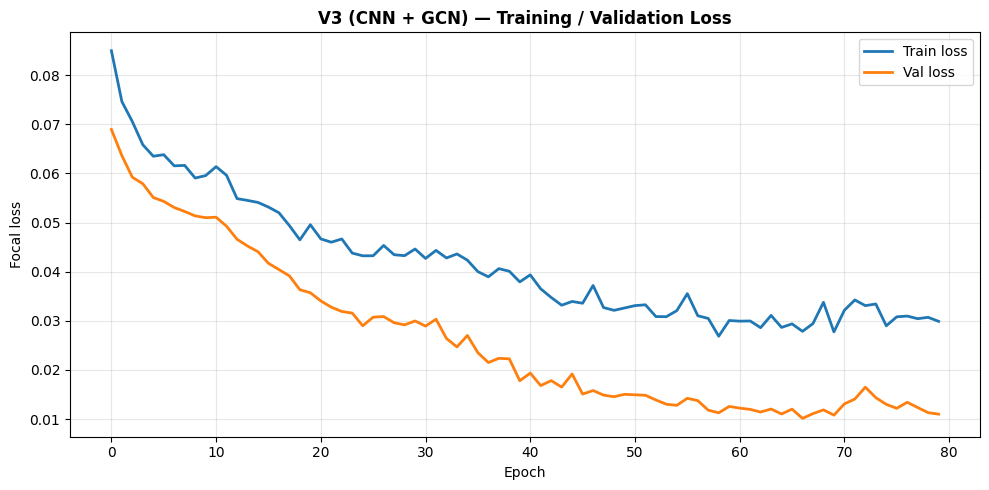

Saved: <repo>/results\Ablation_V3\V3_Loss_Curve.png


In [9]:
plt.figure(figsize=(10,5))
plt.plot(history['train_loss'], label='Train loss', linewidth=2)
plt.plot(history['val_loss'],   label='Val loss',   linewidth=2)
plt.xlabel('Epoch'); plt.ylabel('Focal loss')
plt.title('V3 (CNN + GCN) — Training / Validation Loss', fontweight='bold')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'V3_Loss_Curve.png')
plt.savefig(save_p, dpi=600, bbox_inches='tight'); plt.show()
print('Saved:', save_p)


## CELL 7B — Training Accuracy Curve

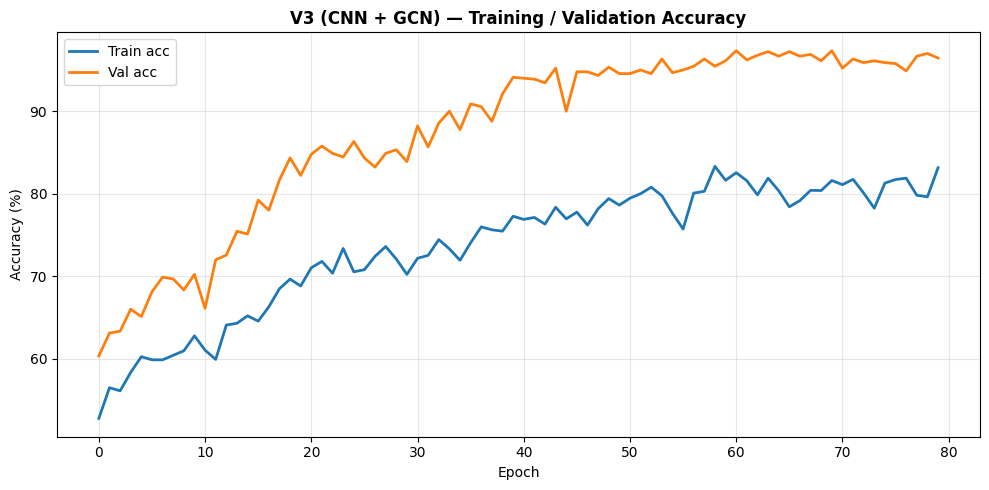

Saved: <repo>/results\Ablation_V3\V3_Accuracy_Curve.png


In [10]:
plt.figure(figsize=(10,5))
plt.plot([a*100 for a in history['train_acc']], label='Train acc', linewidth=2)
plt.plot([a*100 for a in history['val_acc']],   label='Val acc',   linewidth=2)
plt.xlabel('Epoch'); plt.ylabel('Accuracy (%)')
plt.title('V3 (CNN + GCN) — Training / Validation Accuracy', fontweight='bold')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'V3_Accuracy_Curve.png')
plt.savefig(save_p, dpi=600, bbox_inches='tight'); plt.show()
print('Saved:', save_p)


## CELL 7C — Validation AUC-ROC Curve

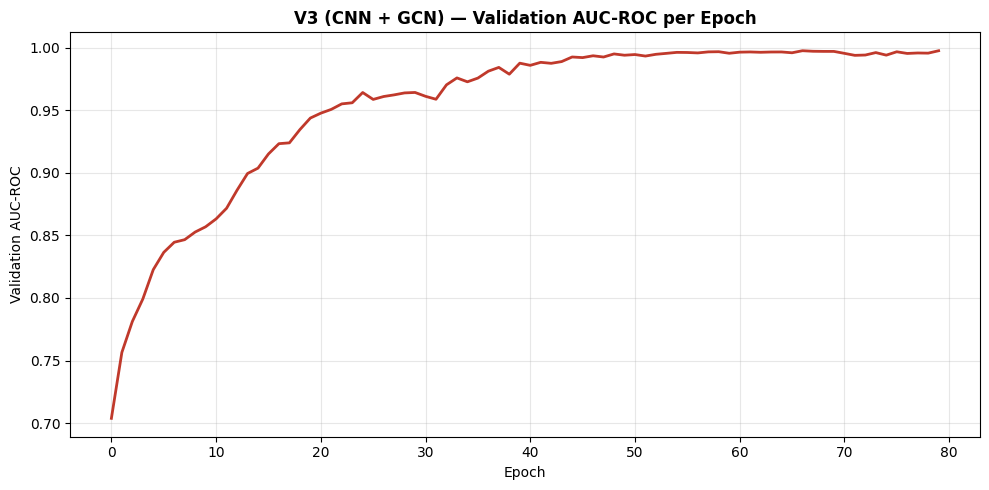

Saved: <repo>/results\Ablation_V3\V3_Validation_AUC_Curve.png


In [11]:
plt.figure(figsize=(10,5))
plt.plot(history['val_auc'], color='#c0392b', linewidth=2)
plt.xlabel('Epoch'); plt.ylabel('Validation AUC-ROC')
plt.title('V3 (CNN + GCN) — Validation AUC-ROC per Epoch', fontweight='bold')
plt.grid(alpha=0.3); plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'V3_Validation_AUC_Curve.png')
plt.savefig(save_p, dpi=600, bbox_inches='tight'); plt.show()
print('Saved:', save_p)


## CELL 7D — Confusion Matrix (TTA×5)

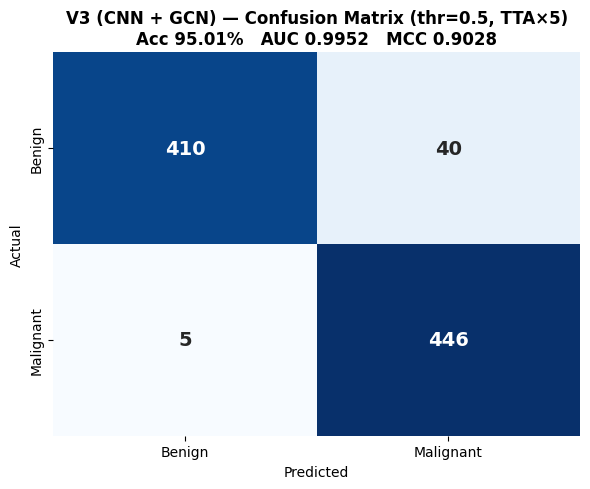

Saved: <repo>/results\Ablation_V3\V3_Confusion_Matrix.png


In [12]:
cm = confusion_matrix(all_labels_test, all_preds_test)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            cbar=False, annot_kws={'size':14, 'weight':'bold'})
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title(f'V3 (CNN + GCN) — Confusion Matrix (thr=0.5, TTA×5)\n'
          f'Acc {acc_tta*100:.2f}%   AUC {auc_tta:.4f}   MCC {mcc_tta:.4f}',
          fontweight='bold')
plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'V3_Confusion_Matrix.png')
plt.savefig(save_p, dpi=600, bbox_inches='tight'); plt.show()
print('Saved:', save_p)


## CELL 7E — ROC Curve

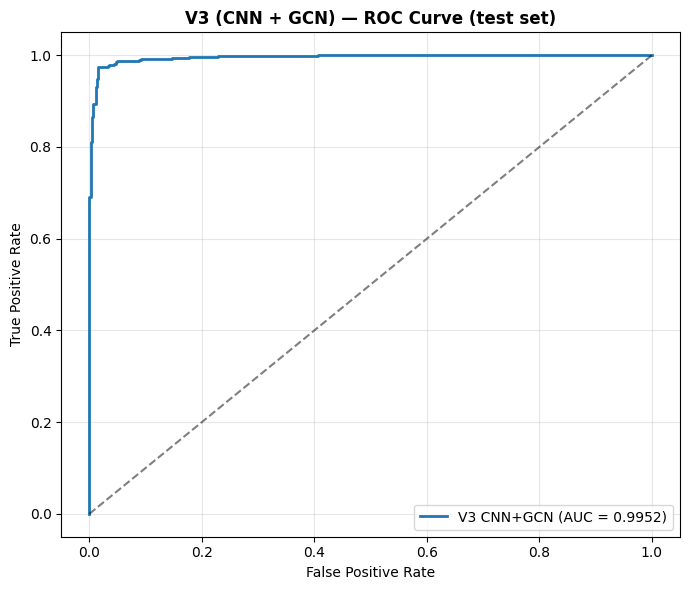

Saved: <repo>/results\Ablation_V3\V3_ROC_Curve.png


In [13]:
plt.figure(figsize=(7,6))
plt.plot(v3_fpr_saved, v3_tpr_saved, lw=2, label=f'V3 CNN+GCN (AUC = {v3_auc_saved:.4f})')
plt.plot([0,1],[0,1], 'k--', alpha=0.5)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('V3 (CNN + GCN) — ROC Curve (test set)', fontweight='bold')
plt.legend(loc='lower right'); plt.grid(alpha=0.3); plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'V3_ROC_Curve.png')
plt.savefig(save_p, dpi=600, bbox_inches='tight'); plt.show()
print('Saved:', save_p)


## CELL 7F — Precision-Recall Curve

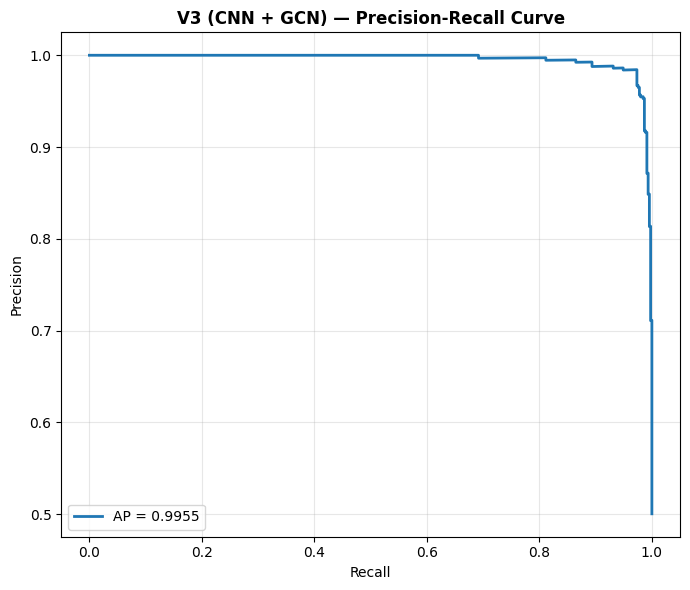

Saved: <repo>/results\Ablation_V3\V3_PR_Curve.png


In [14]:
prec, rec, _ = precision_recall_curve(all_labels_test, all_probs_test)
ap = average_precision_score(all_labels_test, all_probs_test)
plt.figure(figsize=(7,6))
plt.plot(rec, prec, lw=2, label=f'AP = {ap:.4f}')
plt.xlabel('Recall'); plt.ylabel('Precision')
plt.title('V3 (CNN + GCN) — Precision-Recall Curve', fontweight='bold')
plt.legend(loc='lower left'); plt.grid(alpha=0.3); plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'V3_PR_Curve.png')
plt.savefig(save_p, dpi=600, bbox_inches='tight'); plt.show()
print('Saved:', save_p)


## CELL 8 — Final Performance Summary

In [15]:
print('=' * 60)
print(f'  V3 (CNN + GCN) — Final Performance')
print('=' * 60)
print(f'  Test accuracy (TTA×5) : {acc_tta*100:.2f}%')
print(f'  Test AUC-ROC          : {auc_tta:.4f}')
print(f'  MCC                   : {mcc_tta:.4f}')
print(f'  F1                    : {f1_tta:.4f}')
print(f'  Sensitivity           : {sens_tta*100:.2f}%')
print(f'  Specificity           : {spec_tta*100:.2f}%')
print(f'  Best val AUC (epoch)  : {ckpt["best_auc"]:.4f}  (epoch {ckpt["epoch"]})')
print()
print('  Design summary:')
print(f'    Backbone         : EfficientNet-B4 (blocks 0-4 frozen, 5-7 tuned)')
print(f'    CNN proj dim     : {CONFIG["cnn_proj_dim"]}')
print(f'    GAT branch       : NONE')
print(f'    GCN branch       : 3-layer, hidden {CONFIG["gcn_hidden_dim"]} -> 128 -> 64')
print(f'    Fusion           : concat 512 + 64 = 576  (NO SE gate)')
print(f'    Head hidden dim  : {CONFIG["head_hidden_dim"]}')
print(f'    Epochs / patience: {CONFIG["num_epochs"]} / {CONFIG["patience"]}   (matched)')
print()
print('  All plots saved as PNG (600 DPI) in:', CONFIG['output_dir'])
print('=' * 60)


  V3 (CNN + GCN) — Final Performance
  Test accuracy (TTA×5) : 95.01%
  Test AUC-ROC          : 0.9952
  MCC                   : 0.9028
  F1                    : 0.9520
  Sensitivity           : 98.89%
  Specificity           : 91.11%
  Best val AUC (epoch)  : 0.9975  (epoch 67)

  Design summary:
    Backbone         : EfficientNet-B4 (blocks 0-4 frozen, 5-7 tuned)
    CNN proj dim     : 512
    GAT branch       : NONE
    GCN branch       : 3-layer, hidden 256 -> 128 -> 64
    Fusion           : concat 512 + 64 = 576  (NO SE gate)
    Head hidden dim  : 128
    Epochs / patience: 80 / 15   (matched)

  All plots saved as PNG (600 DPI) in: <repo>/results\Ablation_V3
